# CPE 486/586 – Homework 5
**Name:** Shayan Rajput  
**UAH Charger ID / email:** sr1826@uah.edu

**PyPI package keyword:**  ***redkeymon*** https://pypi.org/project/redkeymon/  

**GitHub repo URL:** https://github.com/redkeymongh/redkeymon/tree/main/src/redkeymon/model  


In [1]:
!pip install -q onnx onnxruntime
!pip install -q git+https://github.com/redkeymongh/redkeymon.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


# Theory

## Q1. Distance between hyperplanes
 The distance is 12 / ‖w‖ . Both hyperplanes have the same normal w so they're parallel.

## Q2. Avoiding overfitting in SVM
- **Use the soft-margin formulation** instead of hard margin. Introduce slack variables $\xi_i \ge 0$:
$$\min_{w,b,\xi}\ \tfrac12\|w\|^2 + C\sum_i \xi_i \quad \text{s.t. } y_i(w^\top x_i + b) \ge 1-\xi_i .$$
  A hard-margin SVM bends itself to separate every point (including noise/outliers); the soft margin allows some violations in exchange for a wider margin.
- **Tune the regularization parameter $C$** (smaller $C$ → stronger regularization, wider margin, less overfitting) using cross-validation.
- **Choose/tune the kernel carefully:** prefer a simpler kernel (linear, low-degree polynomial) when it suffices; for RBF, keep $\gamma$ small enough that the boundary is not wrapped around individual points. Tune $C$ and $\gamma$ jointly with grid search + k-fold CV.
- Supporting practices: feature scaling, removing irrelevant features / dimensionality reduction (e.g., PCA), and getting more training data. A large fraction of training points becoming support vectors is a warning sign of overfitting.
## Q3. K-means, one iteration
Initial centroids $\mu_1=(1,1)$, $\mu_2=(5,5)$.

**Assignment step** (Euclidean distance):

| Point | $d(\cdot,\mu_1)$ | $d(\cdot,\mu_2)$ | Cluster |
|---|---|---|---|
| (1,2) | $\sqrt{0+1}=1$ | $\sqrt{16+9}=5$ | 1 |
| (2,1) | $\sqrt{1+0}=1$ | $\sqrt{9+16}=5$ | 1 |
| (4,5) | $\sqrt{9+16}=5$ | $\sqrt{1+0}=1$ | 2 |
| (5,4) | $\sqrt{16+9}=5$ | $\sqrt{0+1}=1$ | 2 |

**Update step:**
$\mu_1 = \left(\frac{1+2}{2},\frac{2+1}{2}\right) = (1.5,\,1.5)$, $\quad\mu_2 = \left(\frac{4+5}{2},\frac{5+4}{2}\right) = (4.5,\,4.5)$.

After one iteration: Cluster 1 = {(1,2),(2,1)} with centroid (1.5, 1.5); Cluster 2 = {(4,5),(5,4)} with centroid (4.5, 4.5). (A second iteration would not change the assignments, so the algorithm has converged.)

## Q4. Anomaly detection with clustering
Flag points that are far from every centroid, labelled noise by DBSCAN, or in tiny clusters.

1. **Distance-to-centroid (K-means):** fit K-means on (mostly normal) data, compute each point's distance to its nearest centroid, and flag points whose distance exceeds a threshold (e.g., a high percentile of training distances, or mean + 3σ per cluster).
2. **Density-based (DBSCAN/HDBSCAN):** points that are not core or border points of any cluster are labelled *noise* — these are the anomalies directly.
3. **Small/sparse clusters:** clusters with very few members (or low density) are treated as anomalous groups (e.g., CBLOF – cluster-based local outlier factor).
4. **Probabilistic (Gaussian Mixture Models):** fit a GMM and flag points with low likelihood $p(x)$.

## Q5. Single neuron forward pass
$$z = w_1x_1 + w_2x_2 + w_3x_3 + b = (0.6)(0.5) + (-0.3)(0.8) + (0.4)(0.2) + 0.1$$
$$= 0.30 - 0.24 + 0.08 + 0.10 = 0.24$$
$$a = \text{ReLU}(0.24) = \max(0, 0.24) = \boxed{0.24}$$

## Q6. Neural network by hand
Architecture 2 → 3 → 1, sigmoid everywhere, no bias, $\eta=0.05$.
$W^{[1]} = \begin{bmatrix}0.1&0.3\\0.2&0.4\\0.1&0.5\end{bmatrix}$ (row $j$ = weights into hidden neuron $j$), $W^{[2]}_1=[0.1,0.2,0.1]$.

### 6.1 Forward pass — hidden layer
$z^{[1]}_j = W^{[1]}_j \cdot x$, $a^{[1]}_j=\sigma(z^{[1]}_j)$

| | Sample 1: $x=(2,4)$ | Sample 2: $x=(4,5)$ |
|---|---|---|
| $z^{[1]}_1$ | $0.1(2)+0.3(4)=1.4$ | $0.1(4)+0.3(5)=1.9$ |
| $z^{[1]}_2$ | $0.2(2)+0.4(4)=2.0$ | $0.2(4)+0.4(5)=2.8$ |
| $z^{[1]}_3$ | $0.1(2)+0.5(4)=2.2$ | $0.1(4)+0.5(5)=2.9$ |
| $a^{[1]}_1$ | 0.80218 | 0.86989 |
| $a^{[1]}_2$ | 0.88080 | 0.94268 |
| $a^{[1]}_3$ | 0.90025 | 0.94785 |

### 6.2 Forward pass — output layer
$z^{[2]}_1 = W^{[2]}_1\cdot a^{[1]}$, $\hat y = a^{[2]}_1 = \sigma(z^{[2]}_1)$

| | Sample 1 | Sample 2 |
|---|---|---|
| $z^{[2]}_1$ | $0.1(0.80218)+0.2(0.88080)+0.1(0.90025)=0.34640$ | $0.1(0.86989)+0.2(0.94268)+0.1(0.94785)=0.37031$ |
| $a^{[2]}_1=\hat y$ | 0.58574 | 0.59153 |

### 6.3 Average loss
Using the given loss literally with $y^{(1)}=-1,\ y^{(2)}=1$:
- Sample 1: $L^{(1)} = -[(-1)\ln(0.58574) + (1-(-1))\ln(1-0.58574)] = -[0.53490 - 1.76258] = 1.22768$
- Sample 2: $L^{(2)} = -[(1)\ln(0.59153) + 0] = 0.52504$

$$L = \tfrac12(1.22768 + 0.52504) = \boxed{0.87636}$$

*(Note: binary cross-entropy is normally used with labels in {0,1}; with $y=-1$ the "loss" is not a proper probability-based loss, but the problem asks us to use the given values, so they are plugged in directly.)*

### 6.4 Backward pass — update $W^{[2]}_1$
Chain rule: $\nabla_{W^{[2]}}L^{(i)} = \dfrac{\partial L}{\partial \hat y^{(i)}}\cdot \hat y^{(i)}(1-\hat y^{(i)})\cdot a^{[1](i)}$

| | Sample 1 | Sample 2 |
|---|---|---|
| $\partial L/\partial\hat y = -\frac{y}{\hat y}+\frac{1-y}{1-\hat y}$ | $\frac{1}{0.58574}+\frac{2}{0.41426}=6.53517$ | $-\frac{1}{0.59153}=-1.69052$ |
| $\partial\hat y/\partial z = \hat y(1-\hat y)$ | 0.24265 | 0.24162 |
| $\partial L/\partial z^{[2]}$ | 1.58574 | −0.40847 |
| gradient $= \partial L/\partial z \cdot a^{[1]}$ | [1.27206, 1.39672, 1.42757] | [−0.35532, −0.38505, −0.38716] |

Average gradient: $\nabla_{W^{[2]}}L = [0.45837,\ 0.50583,\ 0.52020]$

Update: $W^{[2]}_1 \leftarrow W^{[2]}_1 - 0.05\,\nabla L$
$$W^{[2]}_1 = [0.1-0.02292,\ 0.2-0.02529,\ 0.1-0.02601] = \boxed{[0.07708,\ 0.17471,\ 0.07399]}$$

The cell below verifies these numbers with NumPy.

In [2]:
import numpy as np
X = np.array([[2, 4], [4, 5]]); Y = np.array([-1, 1])
W1 = np.array([[0.1, 0.3], [0.2, 0.4], [0.1, 0.5]]); W2 = np.array([0.1, 0.2, 0.1]); eta = 0.05
sig = lambda z: 1 / (1 + np.exp(-z))
grads, losses = [], []
for i, (x, y) in enumerate(zip(X, Y), 1):
    z1 = W1 @ x; a1 = sig(z1); z2 = W2 @ a1; a2 = sig(z2)
    print(f"Sample {i}: z1={np.round(z1,5)}, a1={np.round(a1,5)}, z2={z2:.5f}, yhat={a2:.5f}")
    losses.append(-(y*np.log(a2) + (1-y)*np.log(1-a2)))
    dL_dz = (-y/a2 + (1-y)/(1-a2)) * a2*(1-a2)
    grads.append(dL_dz * a1)
    print(f"   loss={losses[-1]:.5f}, grad={np.round(grads[-1],5)}")
g = np.mean(grads, axis=0)
print("Average loss:", round(np.mean(losses), 5))
print("Average gradient:", np.round(g, 5))
print("Updated W2:", np.round(W2 - eta*g, 5))

Sample 1: z1=[1.4 2.  2.2], a1=[0.80218 0.8808  0.90025], z2=0.34640, yhat=0.58574
   loss=1.22768, grad=[1.27206 1.39672 1.42757]
Sample 2: z1=[1.9 2.8 2.9], a1=[0.86989 0.94268 0.94785], z2=0.37031, yhat=0.59153
   loss=0.52504, grad=[-0.35532 -0.38505 -0.38716]
Average loss: 0.87636
Average gradient: [0.45837 0.50583 0.5202 ]
Updated W2: [0.07708 0.17471 0.07399]


## Q7. Dropout
**Dropout** is a regularization technique where, during each training forward pass, every neuron in a layer is independently "switched off" (its output set to 0) with probability $p$ (e.g., 0.2–0.5). A different random sub-network is trained at every mini-batch. In *inverted dropout* (used by PyTorch), surviving activations are scaled by $1/(1-p)$ during training so that at test time dropout is simply turned off and the full network is used with no rescaling.

**Benefits:**
- **Reduces overfitting:** neurons cannot rely on specific other neurons being present, which prevents *co-adaptation* and forces the network to learn redundant, more robust features.
- **Implicit ensemble:** training many thinned sub-networks that share weights approximates averaging an exponential number of models, which improves generalization.
- **Cheap:** adds almost no computational cost and is easy to apply (e.g., `nn.Dropout(p)`), often allowing larger networks to be trained without overfitting.


# Practice

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Diabetes/diabetes.csv"
try:
    df = pd.read_csv(url)
except Exception:
    df = pd.read_csv("diabetes.csv")   # local copy fallback
print(df.shape); df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Q8. PCA on the Diabetes dataset

In [4]:
features = df.drop(columns="Outcome"); y_d = df["Outcome"].values
X_std = StandardScaler().fit_transform(features)

# 8.1 PCA with 2 components
pca2 = PCA(n_components=2).fit(X_std)
Z2 = pca2.transform(X_std)
print("Explained variance ratio (PC1, PC2):", np.round(pca2.explained_variance_ratio_, 4))
print("Total variance explained by 2 PCs: {:.2%}".format(pca2.explained_variance_ratio_.sum()))

Explained variance ratio (PC1, PC2): [0.2618 0.2164]
Total variance explained by 2 PCs: 47.82%


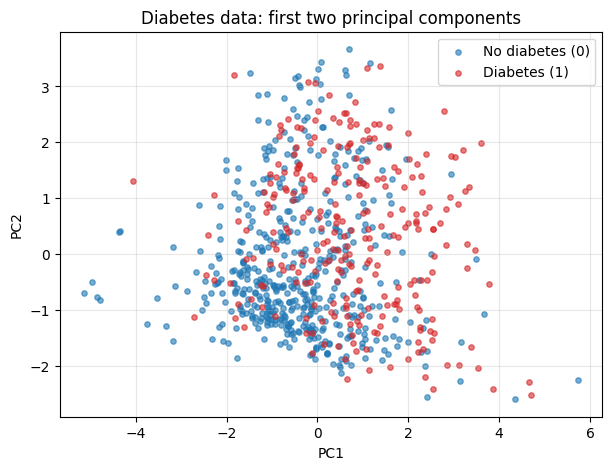

In [5]:
# 8.2 2D plot
plt.figure(figsize=(7,5))
for c, col, lab in [(0,"tab:blue","No diabetes (0)"), (1,"tab:red","Diabetes (1)")]:
    plt.scatter(Z2[y_d==c,0], Z2[y_d==c,1], s=15, alpha=0.6, c=col, label=lab)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Diabetes data: first two principal components")
plt.legend(); plt.grid(alpha=.3); plt.show()

**8.2 Analysis.** Two components capture only about 48% of the variance (≈26% + ≈22%), so a lot of information is discarded. In the plot the two classes overlap heavily: diabetic patients (red) tend to lie more toward larger PC1 values (PC1 is loaded mostly on Glucose, BMI, Age, Insulin, SkinThickness), so there is a visible *trend*, but there is no clear boundary separating the classes. The classes are therefore only weakly distinguishable in 2D. Remember PCA is unsupervised — it finds directions of maximum variance, not of maximum class separation.

In [6]:
# 8.3 PCA with 3 components
pca3 = PCA(n_components=3).fit(X_std)
Z3 = pca3.transform(X_std)
for i, r in enumerate(pca3.explained_variance_ratio_, 1):
    print(f"PC{i}: {r:.2%}")
print("Cumulative: {:.2%}".format(pca3.explained_variance_ratio_.sum()))
print("\nLoadings:")
print(pd.DataFrame(pca3.components_.T, index=features.columns, columns=["PC1","PC2","PC3"]).round(3))

PC1: 26.18%
PC2: 21.64%
PC3: 12.87%
Cumulative: 60.69%

Loadings:
                            PC1    PC2    PC3
Pregnancies               0.128  0.594  0.013
Glucose                   0.393  0.174 -0.468
BloodPressure             0.360  0.184  0.535
SkinThickness             0.440 -0.332  0.238
Insulin                   0.435 -0.251 -0.337
BMI                       0.452 -0.101  0.362
DiabetesPedigreeFunction  0.271 -0.122 -0.433
Age                       0.198  0.621 -0.075


**8.3 Discussion.** The third component adds roughly 13% more explained variance, bringing the cumulative total to about 61%. Its contribution is noticeably smaller than PC1/PC2 (each ≈ 22–26%), and since the eight original features are only weakly correlated the variance is spread out — even three components leave ~39% unexplained. The PC3 loadings (see table) contrast BloodPressure and BMI (positive) against Glucose, DiabetesPedigreeFunction and Insulin (negative), so it captures a direction of variation that PC1 (overall size of most measurements) and PC2 (mainly Age and Pregnancies) did not.

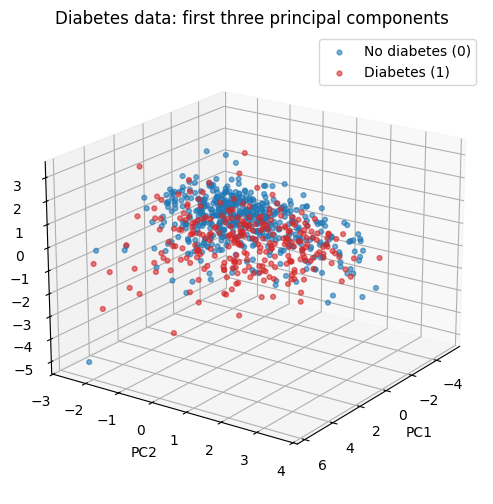

In [7]:
# 8.4 3D plot
from mpl_toolkits.mplot3d import Axes3D  # noqa
fig = plt.figure(figsize=(8,6)); ax = fig.add_subplot(111, projection="3d")
for c, col, lab in [(0,"tab:blue","No diabetes (0)"), (1,"tab:red","Diabetes (1)")]:
    ax.scatter(Z3[y_d==c,0], Z3[y_d==c,1], Z3[y_d==c,2], s=12, alpha=0.6, c=col, label=lab)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("Diabetes data: first three principal components"); ax.legend(); ax.view_init(20, 35); plt.show()

In [8]:
# Quantitative check: how separable are the classes in 2D vs 3D? (5-fold CV logistic regression)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
for name, Z in [("2 PCs", Z2), ("3 PCs", Z3), ("All 8 standardized features", X_std)]:
    acc = cross_val_score(LogisticRegression(max_iter=1000), Z, y_d, cv=5).mean()
    print(f"{name:30s} CV accuracy = {acc:.3f}")

2 PCs                          CV accuracy = 0.724
3 PCs                          CV accuracy = 0.730
All 8 standardized features    CV accuracy = 0.771


**8.4 Analysis.** Adding PC3 gives a little more room to see the two groups, but the red and blue points remain heavily intermixed in the 3D cloud — there is no clean separating surface. The simple linear classifier check above confirms this: 5-fold CV accuracy only moves from 72.4% (2 PCs) to 73.0% (3 PCs), still below the 77.1% obtained with all eight features. So the classes are only marginally more distinguishable in 3D than in 2D; the extra component mostly captures variance that is not related to the Outcome.

## Q9. Transforming data with kernels and SVM

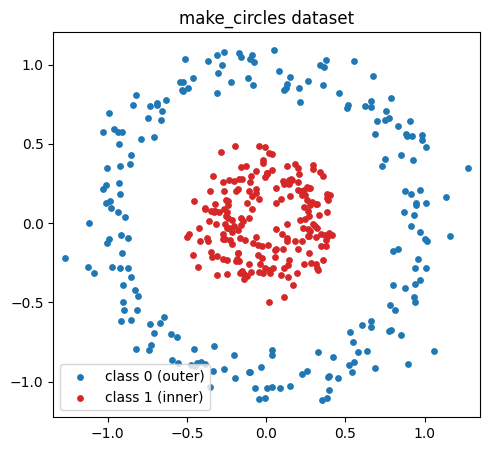

In [9]:
from sklearn.datasets import make_circles
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = make_circles(n_samples=400, noise=0.1, factor=0.3, random_state=1)
plt.figure(figsize=(5.5,5))
plt.scatter(X[y==0,0], X[y==0,1], c="tab:blue", s=15, label="class 0 (outer)")
plt.scatter(X[y==1,0], X[y==1,1], c="tab:red", s=15, label="class 1 (inner)")
plt.axis("equal"); plt.legend(); plt.title("make_circles dataset"); plt.show()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

**9.1** One class forms an inner disk and the other an outer ring surrounding it. A linear SVM can only draw a single straight line (hyperplane) $w^\top x + b = 0$; any line splits the plane into two half-planes, and each half-plane necessarily contains parts of the outer ring *and* possibly the inner disk. The true boundary is a circle ($x_1^2 + x_2^2 \approx r^2$), which is not a linear function of $(x_1,x_2)$, so a linear SVM will perform poorly — little better than guessing.

Linear SVM             train acc = 0.671 | test acc = 0.650 | #support vectors = 277


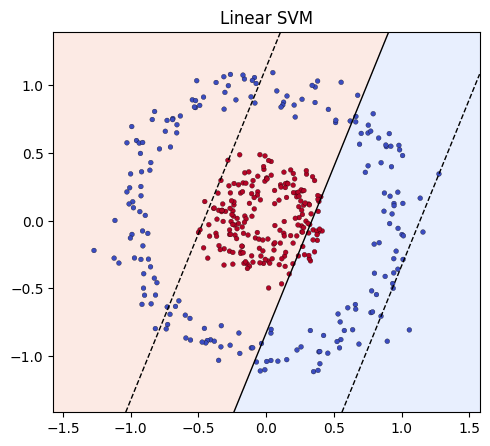

In [10]:
def plot_boundary(model, X, y, title, ax=None):
    ax = ax or plt.gca()
    xx, yy = np.meshgrid(np.linspace(X[:,0].min()-.3, X[:,0].max()+.3, 400),
                         np.linspace(X[:,1].min()-.3, X[:,1].max()+.3, 400))
    Zg = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Zg > 0, alpha=0.2, cmap="coolwarm")
    ax.contour(xx, yy, Zg, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=1)
    ax.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", s=12, edgecolors="k", linewidths=0.2)
    ax.set_title(title); ax.set_aspect("equal")

def report(model, name):
    tr = accuracy_score(y_tr, model.predict(X_tr)); te = accuracy_score(y_te, model.predict(X_te))
    print(f"{name:22s} train acc = {tr:.3f} | test acc = {te:.3f} | #support vectors = {model.n_support_.sum()}")
    return tr, te

# 9.2 Linear SVM
lin = SVC(kernel="linear", C=1.0).fit(X_tr, y_tr)
report(lin, "Linear SVM")
plt.figure(figsize=(5.5,5)); plot_boundary(lin, X, y, "Linear SVM"); plt.show()

**9.2** As predicted, the linear SVM finds only a straight line through the data. Its accuracy is only ≈65–67% (vs. 50% for a coin flip), and nearly every training point (277 of 280) becomes a support vector — a sign the model cannot fit the structure. A line can never separate a ring from the disk it encloses; the small gain over 50% comes only from the noise making the classes slightly unbalanced on either side of the line.

RBF SVM (gamma=1)      train acc = 1.000 | test acc = 1.000 | #support vectors = 30


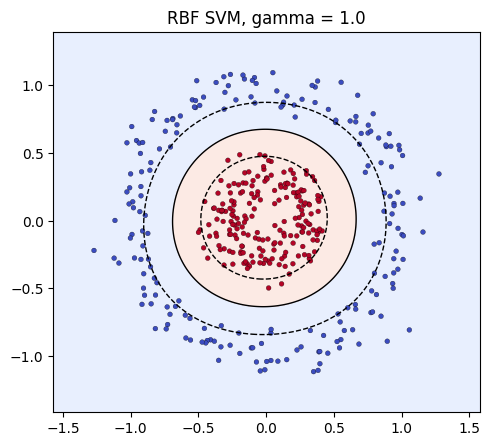

In [11]:
# 9.3 RBF SVM, gamma = 1.0
rbf1 = SVC(kernel="rbf", gamma=1.0, C=1.0).fit(X_tr, y_tr)
report(rbf1, "RBF SVM (gamma=1)")
plt.figure(figsize=(5.5,5)); plot_boundary(rbf1, X, y, "RBF SVM, gamma = 1.0"); plt.show()

**9.3** The RBF SVM achieves near-perfect accuracy and draws a roughly circular boundary between the inner and outer classes. The RBF kernel $K(x,x') = \exp(-\gamma\|x-x'\|^2)$ is an inner product in an (infinite-dimensional) feature space $\phi(x)$. In that space the classes become linearly separable, and the SVM finds a linear hyperplane there; projected back to the original 2-D input space this hyperplane becomes the closed, circular curve seen above. Thanks to the *kernel trick*, the SVM never computes $\phi(x)$ explicitly — it only needs the pairwise kernel values. (Intuitively, a mapping as simple as adding $x_1^2 + x_2^2$ as a third feature would already make the data linearly separable.)

RBF SVM (gamma=0.1)    train acc = 0.996 | test acc = 1.000 | #support vectors = 244
RBF SVM (gamma=1.0)    train acc = 1.000 | test acc = 1.000 | #support vectors = 30
RBF SVM (gamma=10)     train acc = 1.000 | test acc = 1.000 | #support vectors = 51


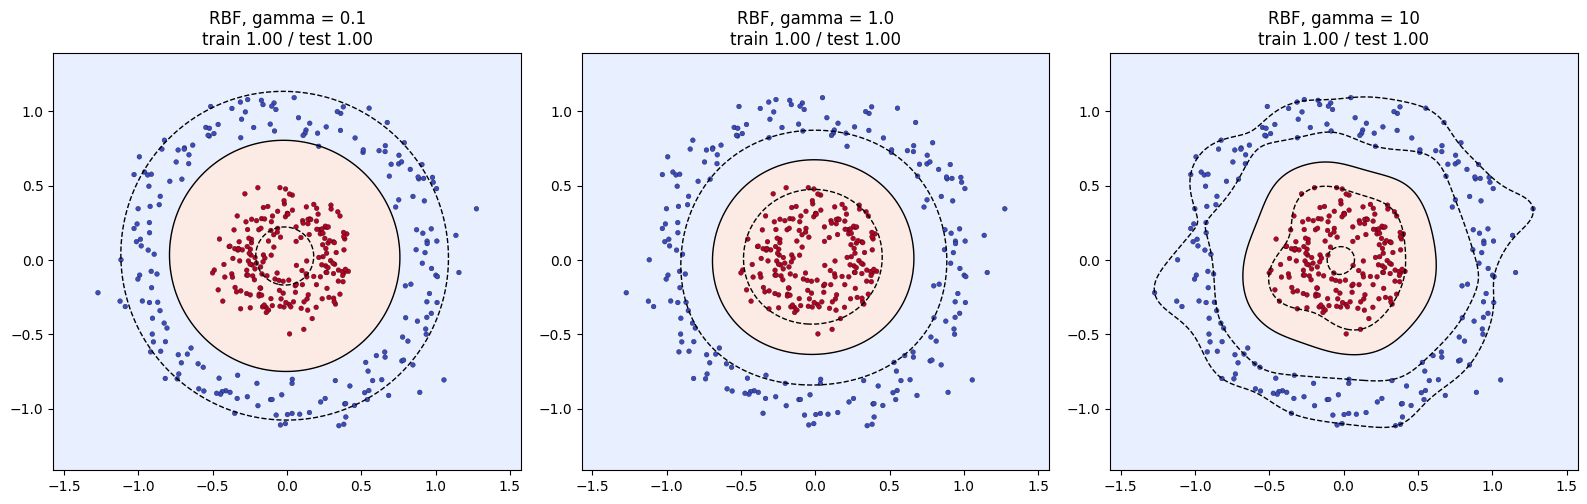

In [12]:
# 9.4 Effect of gamma
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, g in zip(axes, [0.1, 1.0, 10]):
    m = SVC(kernel="rbf", gamma=g, C=1.0).fit(X_tr, y_tr)
    tr, te = report(m, f"RBF SVM (gamma={g})")
    plot_boundary(m, X, y, f"RBF, gamma = {g}\ntrain {tr:.2f} / test {te:.2f}", ax)
plt.tight_layout(); plt.show()

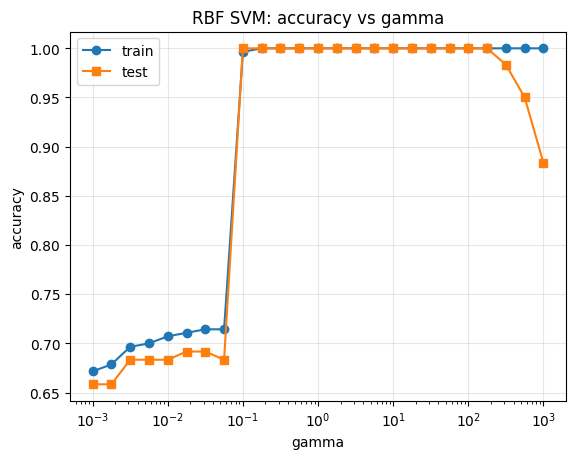

RBF SVM (gamma=0.01)   train acc = 0.707 | test acc = 0.683 | #support vectors = 280
RBF SVM (gamma=100)    train acc = 1.000 | test acc = 1.000 | #support vectors = 198


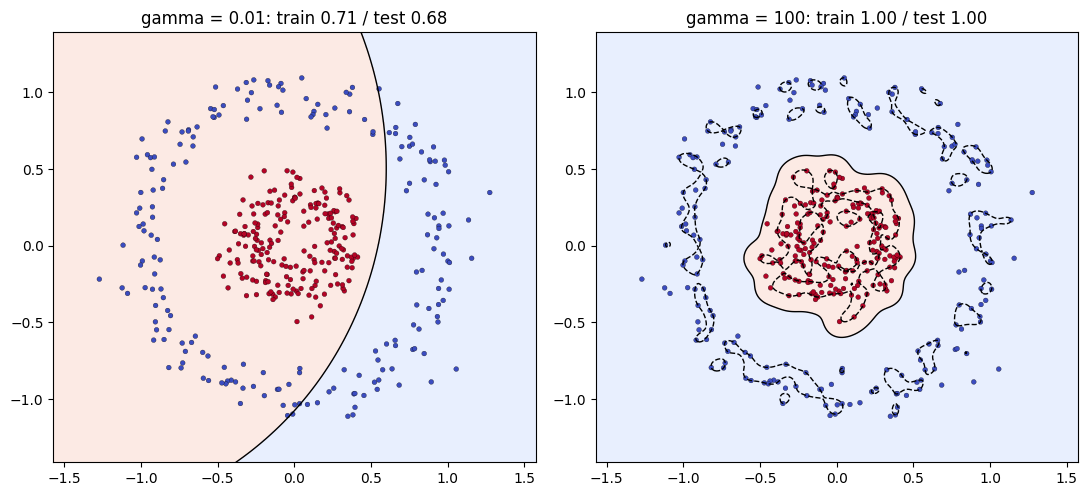

In [13]:
# Making over-/under-fitting more visible: sweep gamma over a wide range
gammas = np.logspace(-3, 3, 25); tr_acc, te_acc = [], []
for g in gammas:
    m = SVC(kernel="rbf", gamma=g, C=1.0).fit(X_tr, y_tr)
    tr_acc.append(m.score(X_tr, y_tr)); te_acc.append(m.score(X_te, y_te))
plt.semilogx(gammas, tr_acc, "o-", label="train"); plt.semilogx(gammas, te_acc, "s-", label="test")
plt.xlabel("gamma"); plt.ylabel("accuracy"); plt.title("RBF SVM: accuracy vs gamma"); plt.legend(); plt.grid(alpha=.3); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, g in zip(axes, [0.01, 100]):
    m = SVC(kernel="rbf", gamma=g, C=1.0).fit(X_tr, y_tr)
    tr, te = report(m, f"RBF SVM (gamma={g})")
    plot_boundary(m, X, y, f"gamma = {g}: train {tr:.2f} / test {te:.2f}", ax)
plt.tight_layout(); plt.show()

**9.4 Discussion.** $\gamma$ controls the reach of each training point's influence: $K(x,x') = \exp(-\gamma\|x-x'\|^2)$.

- **Small $\gamma$ (0.1): wide kernel, smooth boundary → tendency to *underfit*.** Every support vector influences a large region, so the decision function is very smooth. Because the circles are well separated, $\gamma=0.1$ still classifies almost everything correctly (99.6% train / 100% test), but its boundary is a very broad, soft curve with a wide margin and it needs 244 support vectors — the model is "stretching" to bend enough. Pushing $\gamma$ lower (0.01, shown above) makes the model behave almost like a linear classifier and accuracy collapses to ≈68–71% — clear underfitting (high bias).
- **Large $\gamma$ (10): narrow kernel, wiggly boundary → tendency to *overfit*.** Each support vector influences only its immediate neighborhood, so the boundary hugs the inner cluster more tightly and starts to follow individual points (51 support vectors vs. 30 at $\gamma=1$). On this clean, well-separated dataset test accuracy is still 100%, but at $\gamma=100$ the boundary breaks into small islands around training points and 198 of 280 points become support vectors: the model is memorizing training points rather than learning the circle — high variance. With noisier or overlapping data this would show up as a drop in test accuracy.
- **$\gamma = 1$** sits in the sweet spot: a smooth, nearly circular boundary with high train *and* test accuracy.

In practice $\gamma$ is tuned jointly with $C$ using cross-validation, picking the value where validation accuracy peaks (see the accuracy vs. gamma curve).

## Q10. K-means on the half-moon dataset

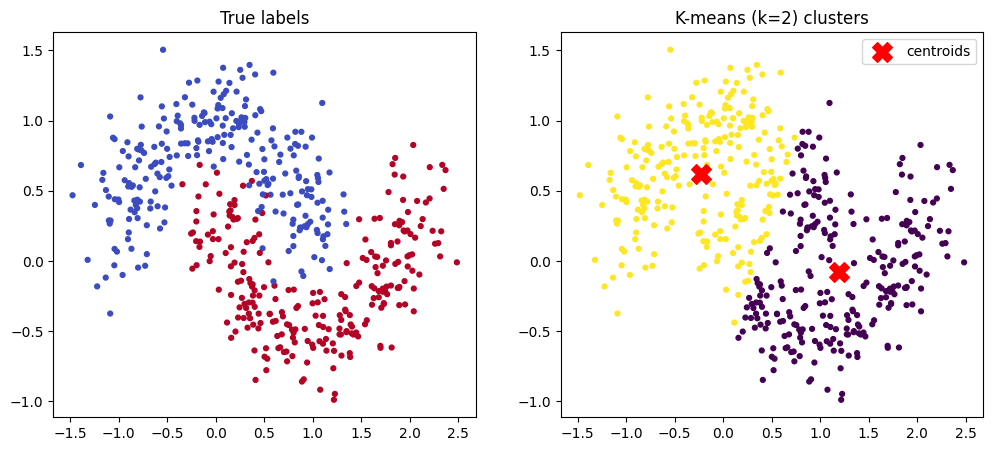

,value
Adjusted Rand Index,0.2773
V-measure,0.2122
Silhouette Score,0.4689
Calinski-Harabasz Index,664.0788


In [14]:
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, v_measure_score, silhouette_score, calinski_harabasz_score

Xm, ym = make_moons(n_samples=500, noise=0.2, random_state=42)
km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Xm)
labels = km.labels_

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(Xm[:,0], Xm[:,1], c=ym, cmap="coolwarm", s=12); axes[0].set_title("True labels")
axes[1].scatter(Xm[:,0], Xm[:,1], c=labels, cmap="viridis", s=12)
axes[1].scatter(*km.cluster_centers_.T, c="red", marker="X", s=200, label="centroids")
axes[1].set_title("K-means (k=2) clusters"); axes[1].legend(); plt.show()

metrics = {
    "Adjusted Rand Index": adjusted_rand_score(ym, labels),
    "V-measure": v_measure_score(ym, labels),
    "Silhouette Score": silhouette_score(Xm, labels),
    "Calinski-Harabasz Index": calinski_harabasz_score(Xm, labels),
}
pd.Series(metrics).round(4).to_frame("value")

**Interpretation.**
- **ARI** (−1 … 1, 1 = perfect agreement with ground truth, ~0 = random) and **V-measure** (0 … 1, harmonic mean of homogeneity and completeness) are *external* metrics that compare to the true moon labels. Both are low (ARI ≈ 0.28, V-measure ≈ 0.21), meaning K-means recovers the true moons poorly.
- **Silhouette** (−1 … 1) and **Calinski-Harabasz** (higher is better) are *internal* metrics that only look at geometry. They are reasonable (Silhouette ≈ 0.47, Calinski-Harabasz ≈ 664), because K-means does produce two fairly compact, separated *convex* groups.
- The mismatch is the key lesson: K-means assumes spherical/convex clusters and splits the data with a straight line between two centroids, so it cuts through the tips of the interleaving crescents. The internal scores look fine, but the external scores show the true (non-convex) structure is not captured. Density-based (DBSCAN) or spectral clustering would follow the moon shapes much better.

## Q11. Classification with a neural network — `TorchNet`

# I Implemented Bonus

`TorchNet` takes `input_dim` and `output_dim` at initialization (bonus), and provides member functions for standardization, model construction, training, loss plotting, ONNX export and ONNX-based prediction.

- Architecture: `input_dim → 4 → 3 → output_dim`, ReLU hidden activations.
- Loss: binary classification → **`BCEWithLogitsLoss`** (sigmoid + binary cross-entropy in one numerically stable op). The network outputs a single logit; probability = sigmoid(logit).
- Optimizer: Adam, lr = 0.01, 1000 epochs (full-batch).

In [15]:
import warnings; warnings.filterwarnings("ignore", category=DeprecationWarning)
import torch, torch.nn as nn, onnxruntime as ort
from redkeymon.model.neuralnet import TorchNet

In [16]:
X_all = df.drop(columns="Outcome").values; y_all = df["Outcome"].values
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, random_state=42, stratify=y_all)

model = TorchNet(input_dim=X_all.shape[1], output_dim=1)
print(model)
model.fit(X_tr, y_tr, epochs=1000)
print("\nTrain accuracy: {:.3f}".format(accuracy_score(y_tr, model.predict(X_tr))))
print("Test  accuracy: {:.3f}".format(accuracy_score(y_te, model.predict(X_te))))

TorchNet(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=4, bias=True)
    (1): ReLU()
    (2): Linear(in_features=4, out_features=3, bias=True)
    (3): ReLU()
    (4): Linear(in_features=3, out_features=1, bias=True)
  )
  (criterion): BCEWithLogitsLoss()
)
Epoch  200 | loss = 0.4122
Epoch  400 | loss = 0.4019
Epoch  600 | loss = 0.3965
Epoch  800 | loss = 0.3959
Epoch 1000 | loss = 0.3959

Train accuracy: 0.818
Test  accuracy: 0.714


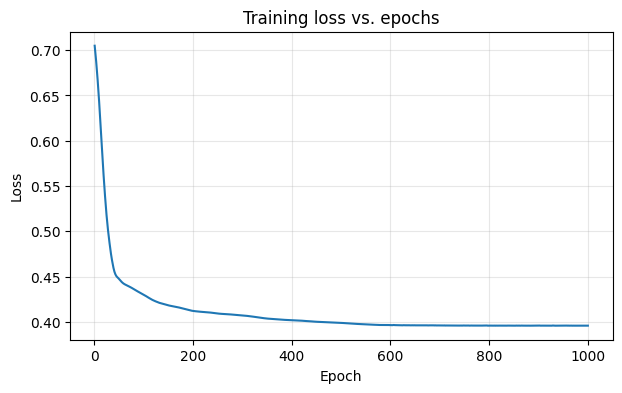

In [17]:
model.plot_loss()

In [18]:
onnx_path = model.save_onnx("torchnet_diabetes.onnx")
import onnx; onnx.checker.check_model(onnx.load(onnx_path)); print("ONNX model check passed")

Model saved to torchnet_diabetes.onnx
ONNX model check passed


In [19]:
# 6. Load the saved ONNX model and predict for the given patient
new_patient = pd.DataFrame([{
    "Pregnancies": 7, "Glucose": 149, "BloodPressure": 73, "SkinThickness": 94,
    "Insulin": 94, "BMI": 32, "DiabetesPedigreeFunction": 0.672, "Age": 45}])
pred, prob = model.predict_onnx(new_patient.values, onnx_path)
print(new_patient.T.rename(columns={0: "value"}))
print(f"\nPredicted probability of diabetes = {prob[0]:.3f}")
print(f"Predicted Outcome = {pred[0]}  ->  {'Diabetes' if pred[0] == 1 else 'No diabetes'}")

                            value
Pregnancies                 7.000
Glucose                   149.000
BloodPressure              73.000
SkinThickness              94.000
Insulin                    94.000
BMI                        32.000
DiabetesPedigreeFunction    0.672
Age                        45.000

Predicted probability of diabetes = 0.962
Predicted Outcome = 1  ->  Diabetes


---
## Reflection Report

UAH Email: sr1826@uah.edu

How I Used the AI Tool: I used Gemini and Claude for this assignment to figure out topics I didn’t know about and to troubleshoot any issues I ran into. I asked the AI agents to get a better understanding and make sure my work is being done in the correct manner to get all the points for the assignment.

Query: Link to chats provided below

How It Helped My Understanding: Using the AI models helped me understand the assignment more since I could ask the agents to troubleshoot any issues that came up for me. Some of the stuff we worked on I didn’t understand so having an agent help me out was beneficial for me to complete the assignment.


How would I approach this without the AI tools: Without the tools I would most likely use Stackoverflow for programming or reference documentation for GitHub and UV to help install the necessary packages I needed for this project. For more technical questions I would have asked the professor on how to perform some actions. I was able to do most of the work myself since I had some programming experince and I have taken Linear Algebra.


Links:

https://claude.ai/share/3939fe83-b706-44c6-a8b7-4d19b66d16af

https://share.gemini.google/8GwRtpkgPtx0

